# Face detection and recognition
*   Face detection
    *   Integral images
    *   Haar-like feature computation
    *   Adaboost 
*   Face recognition
    *   Eigen Faces
    *   PCA and LDA
---

### Face detection using YuNet (using Haar and Adaboost is below)

Image size: 512 x 512
OpenCV version: 5.0.0
Model: /Users/kaisar/Documents/Teaching/UB/2026-2027/MSc/Set6/face_detection_yunet_2023mar.onnx
Detected 1 face(s).
Face 1 - Right eye: (272, 270)
Face 1 - Left eye: (328, 277)
Face 1 - Nose: (310, 313)
Face 1 - Right mouth corner: (271, 342)
Face 1 - Left mouth corner: (311, 349)


[ WARN:0@0.234] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


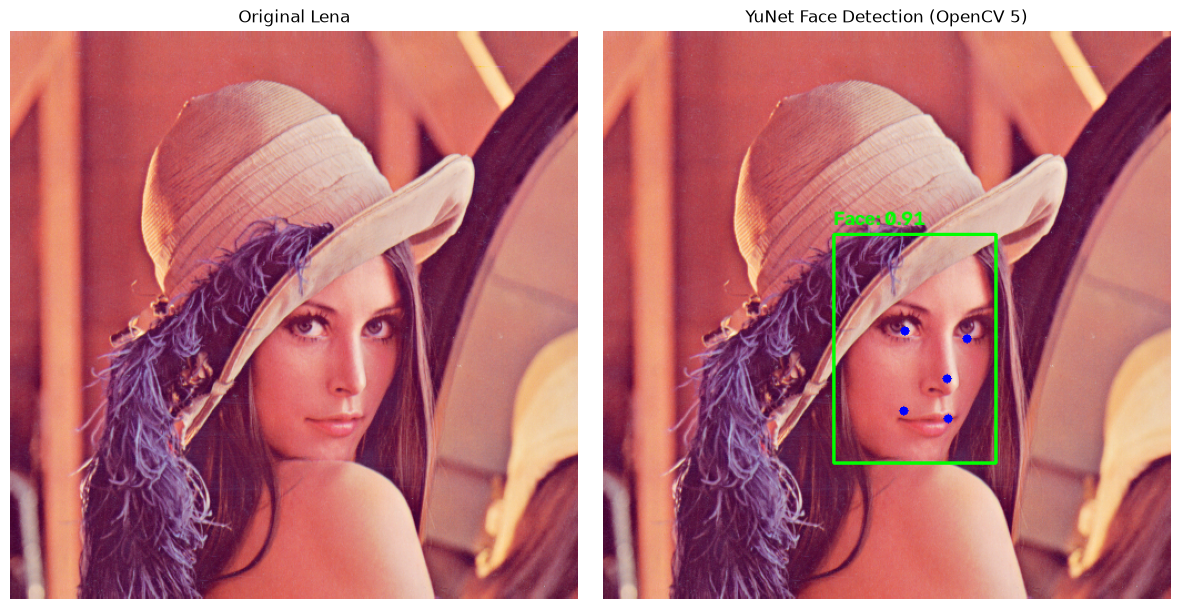

In [1]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request

# --------------------------------------------------
# 1. Load the local image
# --------------------------------------------------
image = cv2.imread("lena.png")

if image is None:
    raise FileNotFoundError(
        "Could not load lena.png. Check that it is in the notebook's working directory."
    )

height, width = image.shape[:2]
print(f"Image size: {width} x {height}")
print(f"OpenCV version: {cv2.__version__}")

# --------------------------------------------------
# 2. Download the pretrained YuNet model if needed
# --------------------------------------------------
model_path = Path("face_detection_yunet_2023mar.onnx")

if not model_path.exists():
    model_url = (
        "https://huggingface.co/opencv/opencv_zoo/resolve/main/"
        "models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
    )

    print("Downloading YuNet model...")
    urllib.request.urlretrieve(model_url, str(model_path))

if not model_path.exists() or model_path.stat().st_size < 100_000:
    raise RuntimeError("Model download failed or the file is incomplete.")

print(f"Model: {model_path.resolve()}")

# --------------------------------------------------
# 3. Create the YuNet face detector
# --------------------------------------------------
detector = cv2.FaceDetectorYN.create(
    str(model_path),
    "",
    (width, height),
    0.6,    # Confidence threshold
    0.3,    # Non-maximum suppression threshold
    5000    # Maximum number of candidates
)

# --------------------------------------------------
# 4. Detect faces
# --------------------------------------------------
retval, faces = detector.detect(image)
result = image.copy()

if faces is None or len(faces) == 0:
    print("No faces detected.")
else:
    print(f"Detected {len(faces)} face(s).")

    landmark_names = [
        "Right eye",
        "Left eye",
        "Nose",
        "Right mouth corner",
        "Left mouth corner"
    ]

    for i, face in enumerate(faces):
        # Face bounding box
        x, y, w, h = face[:4].astype(int)
        confidence = float(face[14])

        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            result,
            f"Face: {confidence:.2f}",
            (x, max(20, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

        # Five facial landmarks
        landmarks = face[4:14].reshape(5, 2).astype(int)

        for (px, py), name in zip(landmarks, landmark_names):
            cv2.circle(result, (px, py), 4, (255, 0, 0), -1)
            print(f"Face {i + 1} - {name}: ({px}, {py})")

# --------------------------------------------------
# 5. Display original and detected image
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Lena")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[1].set_title("YuNet Face Detection (OpenCV 5)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Face Detection using AdaBoost

In [2]:
# Loading necessary libraries (Feel free to add new libraries if you need for any computation)

import numpy as np
from skimage import data, io
import os
import matplotlib
from PIL import Image
from multiprocessing import Pool
from functools import partial
import time
import timeit
from matplotlib import pyplot as plt

### Exercise #1

*   Build a function compute_integral_image that computes the integral image of an input (2D) array. In an integral image each pixel is the sum of all pixels in the original image that are 'left and above' the pixel. See the following example:

```
Original    Integral
+--------   +------------
| 1 2 3 .   | 0  0  0  0 .
| 4 5 6 .   | 0  1  3  6 .
| . . . .   | 0  5 12 21 .
            | . . . . . .
```

*   The integral image must have an additional row and column full of zeros (first row and first column).
*   Plot the output of the integral image for the following array:

```
img_array = np.array([[1,2,2,2,1],[1,2,2,2,1],[1,2,2,2,1],[1,2,2,2,1]])
```

In [3]:
def compute_integral_image(img_arr):
    """
    Calculates the integral image based on the original image data.
    :param img_arr: Image source data
    :type img_arr: numpy.ndarray
    :return Integral image for given image
    :rtype: numpy.ndarray
    """
    # an index of -1 refers to the last row/column
    # since row_sum is calculated starting from (0,0),
    # rowSum(x, -1) == 0 holds for all x
    row_sum = np.zeros(img_arr.shape)
    # we need an additional column and row
    integral_image_arr = np.zeros((img_arr.shape[0] + 1, img_arr.shape[1] + 1))

    # --------------------------------------------------------------------------
    # solution
    #
    # first row and column as zeros
    integral_image_arr[1:, 1:] = np.cumsum(img_arr, axis=0)
    integral_image_arr = np.cumsum(integral_image_arr, axis=1)
    # --------------------------------------------------------------------------


    return integral_image_arr

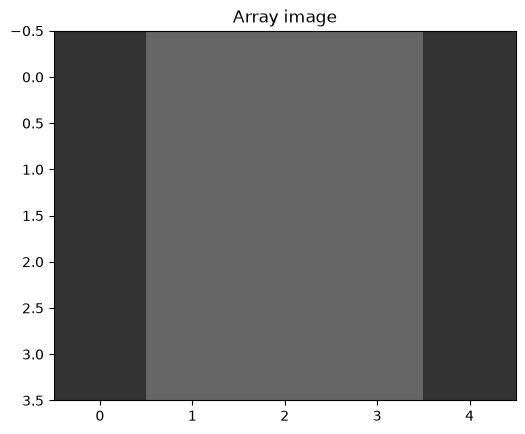

In [4]:
img_array = np.array([[1, 2, 2, 2, 1], [1, 2, 2, 2, 1], [1, 2, 2, 2, 1], [1, 2, 2, 2, 1]])
plt.imshow(img_array, cmap="gray", vmin=0, vmax= 5)
plt.title("Array image")
plt.show()

In [5]:
ii_img_array = compute_integral_image(img_array)
print(ii_img_array)

[[ 0.  0.  0.  0.  0.  0.]
 [ 0.  1.  3.  5.  7.  8.]
 [ 0.  2.  6. 10. 14. 16.]
 [ 0.  3.  9. 15. 21. 24.]
 [ 0.  4. 12. 20. 28. 32.]]


*   Test the function using 'camera' image from the data module. Plot the original image and the integral image.

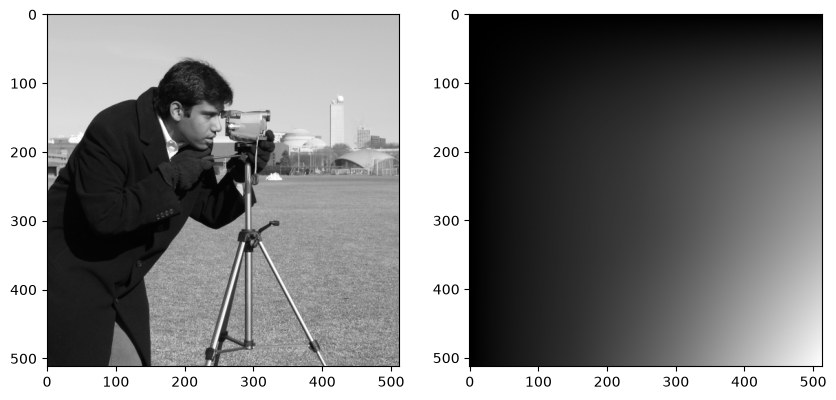

In [6]:
# solution

camera = data.camera()

camera_img_array = compute_integral_image(camera)
    
f, axarr = plt.subplots(ncols=2, nrows=1,figsize=(10,10))
axarr[0].imshow(camera, cmap='gray')
axarr[1].imshow(camera_img_array, cmap='gray', vmin=np.amin(camera_img_array), vmax= np.amax(camera_img_array))
plt.show()

### Exercise #2

*   Create a function sum_region to compute the sum of the pixel intensities within a rectangle using the integral image. The rectangle will be defined using the top left (x, y) and bottom right (x, y) coordinates.

In [7]:
def sum_region(integral_img_arr, top_left, bottom_right):

    # --------------------------------------------------------------------------
    # solution
    #
    A = integral_img_arr[top_left[0], top_left[1]] #Top left position
    B = integral_img_arr[top_left[0], bottom_right[1]] #Bottom left position
    C = integral_img_arr[bottom_right[0], top_left[1]] #Top right position
    D = integral_img_arr[bottom_right[0], bottom_right[1]] #Bottom right position

    # print(A, B, C, D)
    
    return D - C - B + A #Computing the sum of the pixel intensities
    # --------------------------------------------------------------------------

*   Make the following tests:

In [8]:
# result you should get (12)
print(sum_region(ii_img_array, [1, 1], [3, 4]))

12.0


In [9]:
# result you should get (32)
print(sum_region(ii_img_array, [0, 0], [-1, -1]))

32.0


### Exercise #3

*   Build a function load_integral_images to read all the images inside a given folder and compute the integral image of every image

In [10]:
def load_integral_images(path):
    ii_images = []
    for idx, _file in enumerate(os.listdir(path)[1:6]):
        #### Complete here:
        #### Read image
        #### Remember to scale the images (with the max pixel intensity value)
        
        # --------------------------------------------------------------------------
        # solution
        #
        if ".png" in _file:
            image = io.imread(path+ '/' + _file)
            image = image/image.max()
            
            integral_image = compute_integral_image(image)
            integral_image = integral_image/integral_image.max() 
            
            ii_images.append(integral_image)

            if idx % 100 == 0:
                print("Computing image number:",idx)

        # --------------------------------------------------------------------------
    return ii_images


# With this function we are reading each file in the folder, calculating its integral image and after that normalizing the image.
# Finally we put our processed image in the list that we will return

In [11]:
# change paths to your location

root_dir = 'images'

pos_training_path = os.path.join(root_dir, 'train_data/faces')
neg_training_path = os.path.join(root_dir, 'train_data/non_faces')
pos_testing_path = os.path.join(root_dir, 'test_data/faces')
neg_testing_path = os.path.join(root_dir, 'test_data/non_faces')

In [12]:
# solution

print('Loading all the list images')
t0 = time.time()

ii_faces_training = load_integral_images(pos_training_path)
ii_non_faces_training = load_integral_images(neg_training_path)
ii_faces_testing = load_integral_images(pos_testing_path)
ii_non_faces_testing = load_integral_images(neg_testing_path)

print(len(ii_faces_training))
print(len(ii_faces_testing))
print(len(ii_non_faces_training))
print(len(ii_non_faces_testing))

print("Done!")
print('Time needed:', time.time()-t0)

Loading all the list images
Computing image number: 0
Computing image number: 0
Computing image number: 0
Computing image number: 0
5
5
5
5
Done!
Time needed: 0.010968685150146484


*   Visualize a few original images and the corresponding integral images using matplotlib.

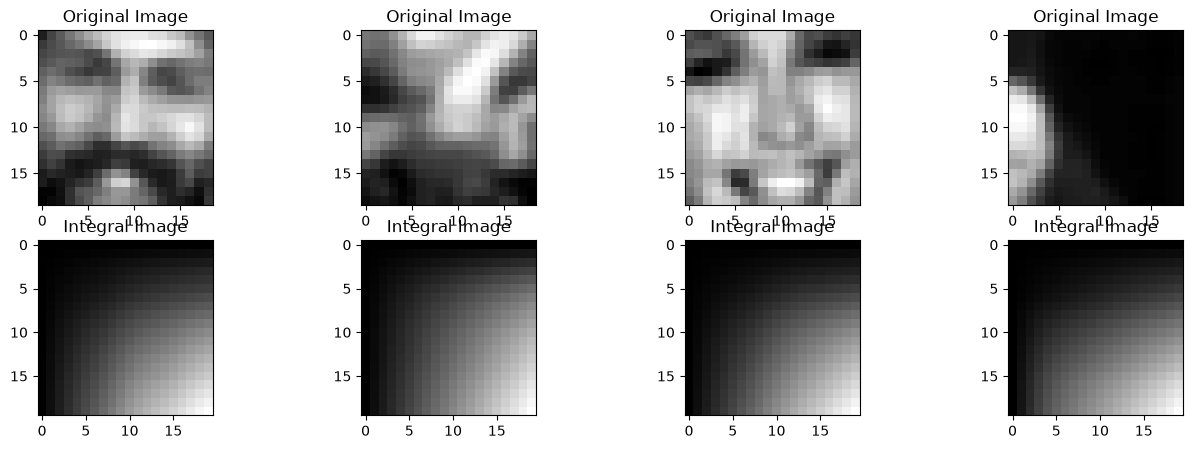

In [13]:
# solution

n = 4

images = [
          os.path.join(pos_training_path, os.listdir(pos_training_path)[1]),
          os.path.join(neg_training_path, os.listdir(neg_training_path)[1]),
          os.path.join(pos_testing_path, os.listdir(pos_testing_path)[1]), 
          os.path.join(neg_testing_path, os.listdir(neg_testing_path)[1])
          ]

integral_images = [
                   ii_faces_training[1],
                   ii_non_faces_training[1],
                   ii_faces_testing[1],
                   ii_non_faces_testing[1]
                   ]

f, axarr = plt.subplots(ncols=n, nrows=2,figsize=(16, 5))
for i in range(n):
    axarr[0][i].imshow(io.imread(images[i]), cmap='gray')
    axarr[0][i].set_title('Original Image')
    axarr[1][i].imshow(integral_images[i], cmap='gray')
    axarr[1][i].set_title('Integral Image')
plt.show()

### Exercise #4

*   Compute the Haar features of an image.

In [14]:
def enum(**enums):
    return type('Enum', (), enums)

FeatureType = enum(TWO_VERTICAL=(1, 2), TWO_HORIZONTAL=(2, 1), THREE_HORIZONTAL=(3, 1), THREE_VERTICAL=(1, 3), FOUR=(2, 2))
FeatureTypes = [FeatureType.TWO_VERTICAL, FeatureType.TWO_HORIZONTAL, FeatureType.THREE_VERTICAL, FeatureType.THREE_HORIZONTAL, FeatureType.FOUR]

In [15]:
class HaarLikeFeature(object):
    """
    Class representing a haar-like feature.
    """

    def __init__(self, feature_type, position, width, height, threshold, polarity):
        """
        Creates a new haar-like feature.
        :param feature_type: Type of new feature, see FeatureType enum
        :type feature_type: HaarLikeFeature.FeatureTypes
        :param position: Top left corner where the feature begins (x, y)
        :type position: (int, int)
        :param width: Width of the feature
        :type width: int
        :param height: Height of the feature
        :type height: int
        :param threshold: Feature threshold
        :type threshold: float
        :param polarity: polarity of the feature -1 or 1
        :type polarity: int
        """
        self.type = feature_type
        self.top_left = position
        self.bottom_right = (position[0] + width, position[1] + height)
        self.width = width
        self.height = height
        self.threshold = threshold
        self.polarity = polarity
        self.weight = 1
    
    def get_score(self, int_img):
        """
        Get score for given integral image array.
        :param int_img: Integral image array
        :type int_img: numpy.ndarray
        
        :return: Score for given feature
        :rtype: float
        """
        score = 0
        if self.type == FeatureType.TWO_VERTICAL:
            first = sum_region(int_img, self.top_left, (self.top_left[0] + self.width, int(self.top_left[1] + self.height / 2)))
            second = sum_region(int_img, (self.top_left[0], int(self.top_left[1] + self.height / 2)), self.bottom_right)
            score = first - second
        elif self.type == FeatureType.TWO_HORIZONTAL:
            first = sum_region(int_img, self.top_left, (int(self.top_left[0] + self.width / 2), self.top_left[1] + self.height))
            second = sum_region(int_img, (int(self.top_left[0] + self.width / 2), self.top_left[1]), self.bottom_right)
            score = first - second
        elif self.type == FeatureType.THREE_HORIZONTAL:
            first = sum_region(int_img, self.top_left, (int(self.top_left[0] + self.width / 3), self.top_left[1] + self.height))
            second = sum_region(int_img, (int(self.top_left[0] + self.width / 3), self.top_left[1]), (int(self.top_left[0] + 2 * self.width / 3), self.top_left[1] + self.height))
            third = sum_region(int_img, (int(self.top_left[0] + 2 * self.width / 3), self.top_left[1]), self.bottom_right)
            score = first - second + third
        elif self.type == FeatureType.THREE_VERTICAL:
            first = sum_region(int_img, self.top_left, (self.bottom_right[0], int(self.top_left[1] + self.height / 3)))
            second = sum_region(int_img, (self.top_left[0], int(self.top_left[1] + self.height / 3)), (self.bottom_right[0], int(self.top_left[1] + 2 * self.height / 3)))
            third = sum_region(int_img, (self.top_left[0], int(self.top_left[1] + 2 * self.height / 3)), self.bottom_right)
            score = first - second + third
        elif self.type == FeatureType.FOUR:
            # top left area
            first = sum_region(int_img, self.top_left, (int(self.top_left[0] + self.width / 2), int(self.top_left[1] + self.height / 2)))
            # top right area
            second = sum_region(int_img, (int(self.top_left[0] + self.width / 2), self.top_left[1]), (self.bottom_right[0], int(self.top_left[1] + self.height / 2)))
            # bottom left area
            third = sum_region(int_img, (self.top_left[0], int(self.top_left[1] + self.height / 2)), (int(self.top_left[0] + self.width / 2), self.bottom_right[1]))
            # bottom right area
            fourth = sum_region(int_img, (int(self.top_left[0] + self.width / 2), int(self.top_left[1] + self.height / 2)), self.bottom_right)
            score = first - second - third + fourth
        return score
    
    def get_vote(self, int_img):
        """
        Get vote of this feature for given integral image.
        :param int_img: Integral image array
        :type int_img: numpy.ndarray
        
        :return: 1 iff this feature votes positively, otherwise -1
        :rtype: int
        """
        score = self.get_score(int_img)
        return self.weight * (1 if score < self.polarity * self.threshold else -1)

In [16]:
def learn(positive_iis, negative_iis, num_classifiers=-1, min_feature_width=1, max_feature_width=-1, min_feature_height=1, max_feature_height=-1):
    """
    Selects a set of classifiers. Iteratively takes the best classifiers based
    on a weighted error.
    :param positive_iis: List of positive integral image examples
    :type positive_iis: list[numpy.ndarray]
    :param negative_iis: List of negative integral image examples
    :type negative_iis: list[numpy.ndarray]
    :param num_classifiers: Number of classifiers to select, -1 will use all
    classifiers
    :type num_classifiers: int
    
    :return: List of selected features
    :rtype: list[HaarLikeFeature.HaarLikeFeature]
    """
    num_pos = len(positive_iis)
    num_neg = len(negative_iis)
    num_imgs = num_pos + num_neg
    img_height, img_width = positive_iis[0].shape

    # Maximum feature width and height default to image width and height
    max_feature_height = img_height if max_feature_height == -1 else max_feature_height
    max_feature_width = img_width if max_feature_width == -1 else max_feature_width

    # Create initial weights and labels
    pos_weights = np.ones(num_pos) * 1. / (2 * num_pos)
    neg_weights = np.ones(num_neg) * 1. / (2 * num_neg)
    weights = np.hstack((pos_weights, neg_weights))
    labels = np.hstack((np.ones(num_pos), np.ones(num_neg) * -1)) 

    images = positive_iis + negative_iis

    # Create features for all sizes and locations
    features = _create_features(img_height, img_width, min_feature_width, max_feature_width, min_feature_height, max_feature_height)
    num_features = len(features)
    feature_indexes = list(range(num_features))

    num_classifiers = num_features if num_classifiers == -1 else num_classifiers

    print('Calculating scores for images..')
    t0 = time.time()
    votes = np.zeros((num_imgs, num_features))
    # Use as many workers as there are CPUs
    # pool = Pool(processes=1)
    # for i in range(num_imgs):
    #     votes[i, :] = np.array(list(pool.map(partial(_get_feature_vote, image=images[i]), features)))
    for i in range(num_imgs):
        votes[i, :] = np.array([feature.get_vote(images[i]) for feature in features])
    
    print('\tTime needed for calculating scores:', time.time()-t0)
    
    # select classifiers
    classifiers = []

    t0 = time.time()
    print('Selecting classifiers..')
    for _ in range(num_classifiers):

        classification_errors = np.zeros(len(feature_indexes))

        # normalize weights
        weights *= 1. / np.sum(weights)

        # select best classifier based on the weighted error
        for f in range(len(feature_indexes)):
            f_idx = feature_indexes[f]
            # classifier error is the sum of image weights where the classifier
            # is right
            error = sum(map(lambda img_idx: weights[img_idx] if labels[img_idx] != votes[img_idx, f_idx] else 0, range(num_imgs)))
            classification_errors[f] = error

        # get best feature, i.e. with smallest error
        min_error_idx = np.argmin(classification_errors)
        best_error = classification_errors[min_error_idx]
        best_feature_idx = feature_indexes[min_error_idx]

        # set feature weight
        best_feature = features[best_feature_idx]
        feature_weight = 0.5 * np.log((1 - best_error) / best_error)
        best_feature.weight = feature_weight

        classifiers.append(best_feature)

        # update image weights
        weights = np.array(list(map(lambda img_idx: weights[img_idx] * np.sqrt((1-best_error)/best_error) if labels[img_idx] != votes[img_idx, best_feature_idx] else weights[img_idx] * np.sqrt(best_error/(1-best_error)), range(num_imgs))))

        # remove feature (a feature can't be selected twice)
        feature_indexes.remove(best_feature_idx)

    print('\tTime needed for Selecting Classifiers:', time.time()-t0,'\n')

    return classifiers


def _create_features(img_height, img_width, min_feature_width, max_feature_width, min_feature_height, max_feature_height):
    print('Creating Haar-like features..')
    t0 = time.time()
    features = []
    for feature in FeatureTypes:
        # FeatureTypes are just tuples
        feature_start_width = max(min_feature_width, feature[0])
        for feature_width in range(feature_start_width, max_feature_width, feature[0]):
            feature_start_height = max(min_feature_height, feature[1])
            for feature_height in range(feature_start_height, max_feature_height, feature[1]):
                for x in range(img_height - max_feature_height):
                  for y in range(img_width - max_feature_width):
                    features.append(HaarLikeFeature(feature, (x, y), feature_width, feature_height, 0, 1))
                    features.append(HaarLikeFeature(feature, (x, y), feature_width, feature_height, 0, -1))
            
    print('\t' + str(len(features)) + ' features created.')
    print('\tTime needed for calculating Haar-like features:', time.time()-t0)
    return features

### Exercise #5

*   Use the learn method to learn a list of two classifiers with the train data. With the learn function you can build a list of classifiers that detect whether an image contains a face or not.

*   Use the following hyperparameters of the features and num_classifiers

In [17]:
num_classifiers = 2
min_feature_height = 8
max_feature_height = 10
min_feature_width = 8
max_feature_width = 10

In [18]:
%%time 
# classifiers = learn(...)

CPU times: user 1e+03 ns, sys: 0 ns, total: 1e+03 ns
Wall time: 2.15 μs


In [19]:
# solution

# %%time 
classifiers = learn(ii_faces_training, ii_non_faces_training, num_classifiers, min_feature_width, max_feature_width, min_feature_height, max_feature_height)

Creating Haar-like features..
	1800 features created.
	Time needed for calculating Haar-like features: 0.0003211498260498047
Calculating scores for images..
	Time needed for calculating scores: 0.016324996948242188
Selecting classifiers..
	Time needed for Selecting Classifiers: 0.0045931339263916016 



### Exercise #6

*   Make a function for voting with different classifiers
*   Build two functions ensemble_vote and ensemble_vote_all.
*   **ensemble_vote(int_img, classifiers)** has to return a 1 if the majority of the votes of the classifiers is positive and a zero otherwise
*   **ensemble_vote_all(int_imgs, classifiers)** has to loop over the list int_imgs and compute the ensemble_vote for each image in the list. It has to return a list containing all the votes for all the images in int_imgs.


In [20]:
# solution

def ensemble_vote(int_img, classifiers):
    votes = []
    for classifier in classifiers:
        votes.append(classifier.get_vote(int_img))

    return 1 if sum(votes) > 0 else 0

In [21]:
def ensemble_vote_all(int_imgs, classifiers):
    votes = []
    for int_img in int_imgs:
        votes.append(ensemble_vote(int_img, classifiers))

    return votes

*   Use the functions to compute the train and test acurracies for faces and non faces.
*   Print the results in the following format:

```
train results:
Correctly identified Faces: 2129/2429  (87.64923836969946%)
Correctly identified non-Faces: 4276/8548  (50.02339728591484%)

test results:
Correctly identified Faces: 300/472  (63.559322033898304%)
Correctly identified non-Faces: 74/128  (57.8125%)
```

*   It is not required to get this exact results but print the information in this format. It facilitates understanding the results.

In [22]:
# solution

n_imgs = len(ii_faces_training)
result_vote_all = ensemble_vote_all(ii_faces_training, classifiers)
Correctly_identified = sum(result_vote_all)
percent_correct_identified = Correctly_identified / n_imgs * 100 
print("train results:")
print("Correctly identified Faces: ", Correctly_identified ,"/", n_imgs, " (", percent_correct_identified, "%)")


n_imgs = len(ii_non_faces_training)
result_vote_all = ensemble_vote_all(ii_non_faces_training, classifiers)
Correctly_identified = n_imgs-sum(result_vote_all) 
percent_correct_identified = Correctly_identified / n_imgs * 100 
print("Correctly identified non-Faces: ", Correctly_identified ,"/", n_imgs, " (", percent_correct_identified, "%)")

n_imgs = len(ii_faces_testing)
result_vote_all = ensemble_vote_all(ii_faces_testing, classifiers)
Correctly_identified = sum(result_vote_all)
percent_correct_identified = Correctly_identified / n_imgs * 100 
print("test results:")
print("Correctly identified Faces: ", Correctly_identified ,"/", n_imgs, " (", percent_correct_identified, "%)")

n_imgs = len(ii_non_faces_testing)
result_vote_all = ensemble_vote_all(ii_non_faces_testing, classifiers)
Correctly_identified = n_imgs-sum(result_vote_all)
percent_correct_identified = Correctly_identified / n_imgs * 100 
print("Correctly identified non-Faces: ", Correctly_identified ,"/", n_imgs, " (", percent_correct_identified, "%)")

train results:
Correctly identified Faces:  5 / 5  ( 100.0 %)
Correctly identified non-Faces:  4 / 5  ( 80.0 %)
test results:
Correctly identified Faces:  5 / 5  ( 100.0 %)
Correctly identified non-Faces:  1 / 5  ( 20.0 %)


### Exercise #7

*   Make another test with 20 classifiers instead of 2.
*   Inspect the classification results if you use adaboost with 20 classifiers. *   Use the same hyperameters for the features. Print the results as in the previous exercise.

In [23]:
num_classifiers = 20
min_feature_height = 8
max_feature_height = 10
min_feature_width = 8
max_feature_width = 10

In [24]:
%%time 
#classifiers_20 = learn(...)

CPU times: user 1 μs, sys: 0 ns, total: 1 μs
Wall time: 2.15 μs


In [25]:
classifiers_20 = learn(ii_faces_training, ii_non_faces_training, num_classifiers, min_feature_width, max_feature_width, min_feature_height, max_feature_height)

Creating Haar-like features..
	1800 features created.
	Time needed for calculating Haar-like features: 0.00030422210693359375
Calculating scores for images..
	Time needed for calculating scores: 0.01663804054260254
Selecting classifiers..
	Time needed for Selecting Classifiers: 0.047335147857666016 



### Exercise #8

*   Change the voting functions so that you can set a threshold for deciding a prediction.
*   The threshold value indicates the minimum score for assigning a "positive" label (detect a face).
*   Create the following functions
    *   ensemble_vote_t: returns the final decision of a list of classifiers for a given threshold.
    *   ensemble_vote_all_t: Iterates over a list of integral images and returns the final decision of a list of classifiers for each of the images (for a given threshold).

In [26]:
# solution

def ensemble_vote_t(int_img, classifiers, th):
    votes = []

    for classifier in classifiers:
        votes.append(classifier.get_vote(int_img))

    return 1 if sum(votes) > th else 0

def ensemble_vote_all_t(int_images, classifiers, th):
    votes = []

    for int_img in int_images:
        votes.append(ensemble_vote_t(int_img, classifiers, th))

    return votes

*   Using the list of 20 classifiers compute the following:

    1.   number of correct faces over all faces (in the train data)
    2.   number of correct non faces over all non faces (in the train data)
    3.   number of correct faces over all faces (in the test data)
    4.   number of correct non faces over all non faces (in the test data)

*   The quantities have to be computed for each of the following thresholds:
```
thresholds = np.array([x for x in range(-5,5,1)])/10.
```

In [27]:
# solution

thresholds = np.array([x for x in range(-5,5,1)])/10.
thresholds

array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4])

In [28]:
pcnt_faces_train=[]
pcnt_nofaces_train=[]
pcnt_faces_test=[]
pcnt_nofaces_test=[]
for threshold in thresholds:
    correct_pos_train = sum(ensemble_vote_all_t(ii_faces_training, classifiers_20, threshold))
    total_pos_train = len(ii_faces_training)

    incorrect_neg_train = sum(ensemble_vote_all_t(ii_non_faces_training, classifiers_20, threshold))
    total_neg_train = len(ii_non_faces_training)
    correct_neg_train = total_neg_train - incorrect_neg_train

    print('Threshold = ' + str(threshold) + '\n')
    print('train results:' + '\n')
    print('Correctly identified Faces: ', str(correct_pos_train)+'/'+str(total_pos_train), '(' + str(100*correct_pos_train/total_pos_train) + '%)')
    print('Correctly identified non-Faces: ', str(correct_neg_train)+'/'+str(total_neg_train), '(' + str(100*correct_neg_train/total_neg_train) + '%)')
    print('\n')

    correct_pos_test = sum(ensemble_vote_all_t(ii_faces_testing, classifiers_20, threshold))
    total_pos_test = len(ii_faces_testing)

    incorrect_neg_test = sum(ensemble_vote_all_t(ii_non_faces_testing, classifiers_20, threshold))
    total_neg_test = len(ii_non_faces_testing)
    correct_neg_test = total_neg_test - incorrect_neg_test

    print('test results:' + '\n')
    print('Correctly identified Faces: ', str(correct_pos_test)+'/'+str(total_pos_test), '(' + str(100*correct_pos_test/total_pos_test) + '%)')
    print('Correctly identified non-Faces: ', str(correct_neg_test)+'/'+str(total_neg_test), '(' + str(100*correct_neg_test/total_neg_test) + '%)')

    print('\n')
    print('------------------------------------------------------------')
    print('\n')
    pcnt_faces_train.append(100*correct_pos_train/total_pos_train)
    pcnt_nofaces_train.append(100*correct_neg_train/total_neg_train)
    pcnt_faces_test.append(100*correct_pos_test/total_pos_test)
    pcnt_nofaces_test.append(100*correct_neg_test/total_neg_test)

Threshold = -0.5

train results:

Correctly identified Faces:  5/5 (100.0%)
Correctly identified non-Faces:  5/5 (100.0%)


test results:

Correctly identified Faces:  4/5 (80.0%)
Correctly identified non-Faces:  3/5 (60.0%)


------------------------------------------------------------


Threshold = -0.4

train results:

Correctly identified Faces:  5/5 (100.0%)
Correctly identified non-Faces:  5/5 (100.0%)


test results:

Correctly identified Faces:  4/5 (80.0%)
Correctly identified non-Faces:  3/5 (60.0%)


------------------------------------------------------------


Threshold = -0.3

train results:

Correctly identified Faces:  5/5 (100.0%)
Correctly identified non-Faces:  5/5 (100.0%)


test results:

Correctly identified Faces:  4/5 (80.0%)
Correctly identified non-Faces:  3/5 (60.0%)


------------------------------------------------------------


Threshold = -0.2

train results:

Correctly identified Faces:  5/5 (100.0%)
Correctly identified non-Faces:  5/5 (100.0%)


test r

*   Make a bar plot for 1-4. In the x axis write the threshold value.

Text(0, 0.5, '%')

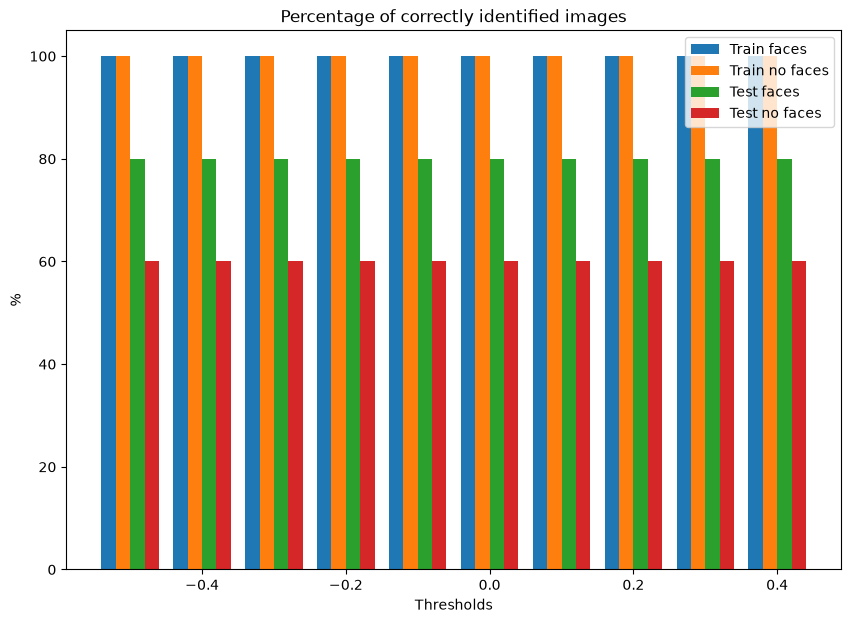

In [29]:
# solution

width = 0.02
fig, ax = plt.subplots(figsize=(10,7))
rects1 = ax.bar(thresholds - 3*width/2, pcnt_faces_train, width, label='Train faces')
rects2 = ax.bar(thresholds - width/2, pcnt_nofaces_train, width, label='Train no faces')
rects3 = ax.bar(thresholds + width/2, pcnt_faces_test, width, label='Test faces')
rects4 = ax.bar(thresholds + 3*width/2, pcnt_nofaces_test, width, label='Test no faces')
ax.legend()
ax.set_title('Percentage of correctly identified images')
ax.set_xlabel('Thresholds')
ax.set_ylabel('%')

# Face Recognition using PCA


In [30]:
# Loading necessary libraries (Feel free to add new libraries if you need for any computation)

from time import time
import logging
import matplotlib.pyplot as plt
import numpy as np
import os

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.datasets import fetch_lfw_people
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

*   Loading the dataset

In [31]:
# Download the data, if not already on disk and load it as numpy arrays

lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

# introspect the images arrays to find the shapes
n_samples, h, w = lfw_people.images.shape

# for machine learning we use the 2 data directly (as relative pixel
# positions info is ignored by this model)
X = lfw_people.data
n_features = X.shape[1]

# the label to predict is the id of the person
y = lfw_people.target
target_names = lfw_people.target_names
n_classes = target_names.shape[0]

print("Total dataset size:")
print("n_samples: %d" % n_samples)
print("n_features: %d" % n_features)
print("n_classes: %d" % n_classes)

Total dataset size:
n_samples: 1288
n_features: 1850
n_classes: 7


*   Creating training and testing set

In [32]:
# split into a training and testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print('Train data shape:', X_train.shape)
print('Test data shape:', X_test.shape)
print('Number of classes in Train set:', np.unique(y_train).shape[0])

Train data shape: (966, 1850)
Test data shape: (322, 1850)
Number of classes in Train set: 7


### Exercise #1: PCA Computation
*   Compute a PCA (eigenfaces) on the face dataset
    *   *Set* number of components to 100

In [33]:
# solution

n_components = 100

print("Extracting the top %d eigenfaces from %d faces" % (n_components, X_train.shape[0]))
t0 = time()

pca = PCA(n_components=n_components, svd_solver='randomized',
          whiten=True).fit(X_train)

print("done in %0.3fs" % (time() - t0))

Extracting the top 100 eigenfaces from 966 faces
done in 0.041s


*   Reshape the components output of pca to obtain the eigen faces

In [34]:
# solution

eigenfaces = pca.components_.reshape((n_components, h, w))
print(eigenfaces.shape)

(100, 50, 37)


*   Project the training and testing faces data on the orthonormal basis

In [35]:
# solution

print("Projecting the input data on the eigenfaces orthonormal basis")
t0 = time()

X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

print("done in %0.3fs" % (time() - t0))

Projecting the input data on the eigenfaces orthonormal basis
done in 0.005s


*   Plot the most significative eigenfaces (Show the top 12 eigenfaces) as a matplotlib

In [36]:
# solution
# reusable functions to plot gallery images

def plot_gallery(images, titles, h, w, n_row=3, n_col=4):
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())


# plot the result of the prediction on a portion of the test set
def title(y_pred, y_test, target_names, i):
    pred_name = target_names[y_pred[i]].rsplit(' ', 1)[-1]
    true_name = target_names[y_test[i]].rsplit(' ', 1)[-1]
    return 'predicted: %s\ntrue:      %s' % (pred_name, true_name)

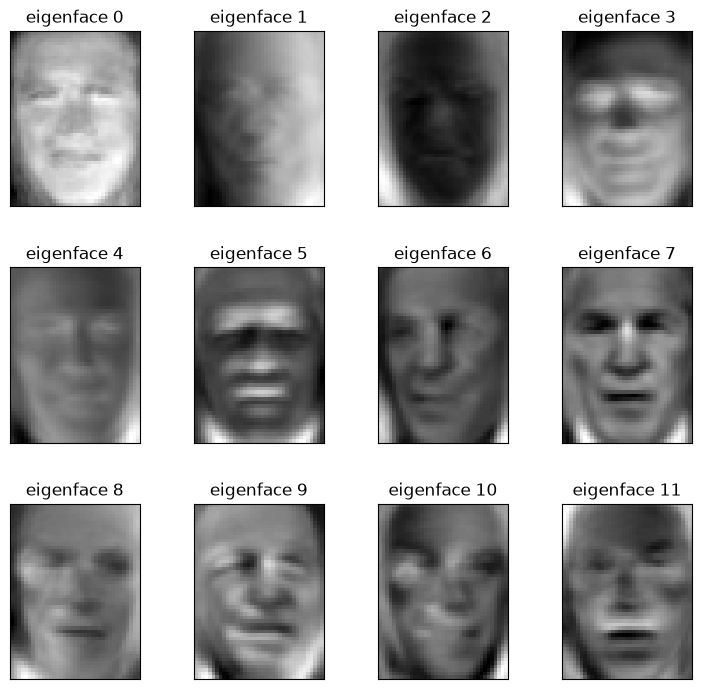

In [37]:
# solution

eigenface_titles = ["eigenface %d" % i for i in range(eigenfaces.shape[0])]
plot_gallery(eigenfaces, eigenface_titles, h, w)

plt.show()

*   Show the total percentage of variance explained by the selected components of the PCA.


In [38]:
# solution

np.sum(pca.explained_variance_ratio_)

np.float32(0.91543627)

*   What are the shortcomings of PCA?

**Solution**

*(Double-click or enter to edit)*

...

### Exercise #2: k-NN Classification

*   Train a k-nearest neighbor model with the eigenfaces using the default parameters

In [39]:
# solution

print("Fitting the classifier to the training set")

t0 = time()

clf = KNeighborsClassifier()
clf = clf.fit(X_train_pca, y_train)

print("done in %0.3fs" % (time() - t0))

Fitting the classifier to the training set
done in 0.001s


*   Predict the test data using the trained classifier

In [40]:
# Quantitative evaluation of the model quality on the test set

print("Predicting people's names on the test set")
t0 = time()

y_pred = clf.predict(X_test_pca)
print("done in %0.3fs" % (time() - t0))

Predicting people's names on the test set
done in 0.063s


### Exercise #3: Quantitative results

*   Compute accuracy, classification report and confusion matrix of the trained classifier

In [41]:
# solution

print('Accuracy using PCA: ', accuracy_score(y_test, y_pred))

Accuracy using PCA:  0.6863354037267081


In [42]:
# solution

print(classification_report(y_test, y_pred, target_names=target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.23      0.23      0.23        13
     Colin Powell       0.78      0.72      0.75        60
  Donald Rumsfeld       0.58      0.52      0.55        27
    George W Bush       0.69      0.92      0.79       146
Gerhard Schroeder       0.71      0.20      0.31        25
      Hugo Chavez       1.00      0.27      0.42        15
       Tony Blair       0.71      0.47      0.57        36

         accuracy                           0.69       322
        macro avg       0.67      0.48      0.52       322
     weighted avg       0.70      0.69      0.66       322



In [43]:
# solution

print(confusion_matrix(y_test, y_pred, labels=range(n_classes)))

[[  3   1   2   6   0   0   1]
 [  4  43   3  10   0   0   0]
 [  2   0  14  10   0   0   1]
 [  2   4   3 135   1   0   1]
 [  1   3   1  11   5   0   4]
 [  1   3   1   5   1   4   0]
 [  0   1   0  18   0   0  17]]


### Exercise #4

*   Use GridSearch to find the optimal value of 'k'.
    *   *Hint: GridSearchCV is available in sklearn.model_selection*
*   What is the accuracy of the best estimator?

In [44]:
# solution

print("Fitting the classifier to the training set")

t0 = time()

param_grid = {'n_neighbors': [3, 5, 7, 9, 11]}

clf = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
clf = clf.fit(X_train_pca, y_train)

print("done in %0.3fs" % (time() - t0))
print("Best estimator found by grid search:")
print(clf.best_estimator_)

print("Predicting people's names on the test set")
t0 = time()

y_pred = clf.predict(X_test_pca)
print("done in %0.3fs" % (time() - t0))

print('Accuracy using PCA: ', accuracy_score(y_test, y_pred))

Fitting the classifier to the training set
done in 0.213s
Best estimator found by grid search:
KNeighborsClassifier(n_neighbors=7)
Predicting people's names on the test set
done in 0.002s
Accuracy using PCA:  0.6335403726708074


### Exercise #5: Qualitative evaluation

*   Plot some of the prediction images using matplotlib subplots (4 x 4). Show the true label and predicted label as the title of each sub plot.

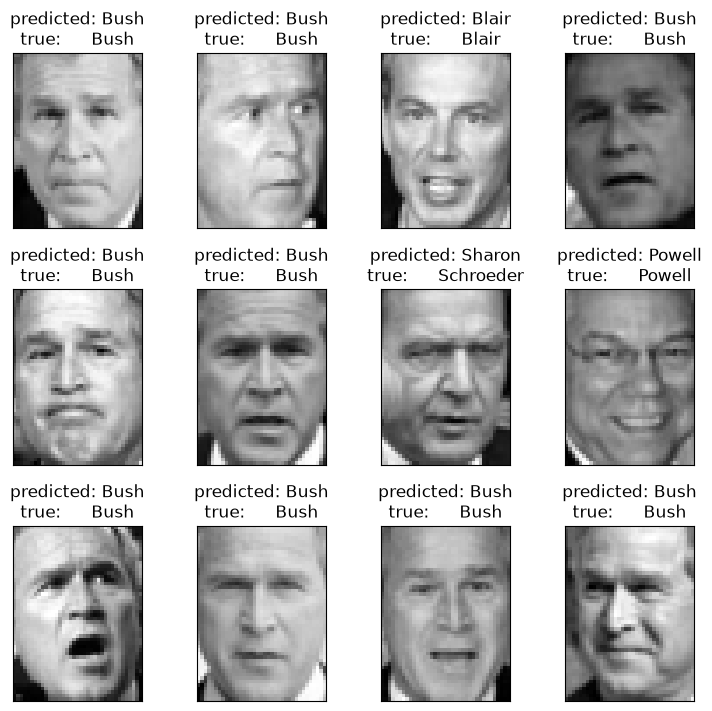

In [45]:
# solution

prediction_titles = [title(y_pred, y_test, target_names, i)
                     for i in range(y_pred.shape[0])]
plot_gallery(X_test, prediction_titles, h, w)